### Croatian binary classifier — XLM-RoBERTa on translated TherapistQA

In [1]:
# Colab setup — mount Drive and install packages
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    %pip install -q transformers datasets accelerate

Mounted at /content/drive


In [2]:
from pathlib import Path

if IS_COLAB:
    PROJECT_ROOT = Path("/content/drive/MyDrive/thesis_stage2")
else:
    PROJECT_ROOT = Path(".")

MODELS_DIR    = PROJECT_ROOT / "models"
RESULTS_DIR   = PROJECT_ROOT / "results"

# === Model choice ===
# Primary run:    "xlm-roberta-base"
# Comparison run: "classla/bcms-bertic" — South-Slavic specialist, often beats XLM-R on Croatian
MODEL_NAME    = "classla/bcms-bertic"
MODEL_TAG     = "bertic"   # short tag for filenames; use "bertic" if MODEL_NAME="classla/bcms-bertic"

# === Hyperparameters — match the English run exactly ===
SEED          = 42
MAX_LEN       = 512
LR            = 2e-5
WEIGHT_DECAY  = 0.01
EPOCHS        = 10
BATCH_TRAIN   = 16
BATCH_EVAL    = 32
WARMUP_RATIO  = 0.1
GRAD_CLIP     = 1.0
EARLY_STOP    = 3

CLASS_WEIGHTED = False    # match the English production run (Chapter 4.4.4 selected unweighted)

# === Dataset — Croatian-translated TherapistQA ===
TRAIN_CSV = PROJECT_ROOT / "therapistqa_bilingual_train.csv"
VAL_CSV   = PROJECT_ROOT / "therapistqa_bilingual_val.csv"
TEST_CSV  = PROJECT_ROOT / "therapistqa_bilingual_test.csv"
TEXT_COL  = "patient_question_hr"
LABEL_COL = "dominant_distortion"

RUN_TAG   = f"tqa_binary_hr_{MODEL_TAG}"
OUT_DIR   = MODELS_DIR / f"binary_therapistqa_{RUN_TAG}"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"MODEL:        {MODEL_NAME}")
print(f"RUN_TAG:      {RUN_TAG}")
print(f"Train: {TRAIN_CSV}")
print(f"Val:   {VAL_CSV}")
print(f"Test:  {TEST_CSV}")
print(f"Out:   {OUT_DIR}")

MODEL:        classla/bcms-bertic
RUN_TAG:      tqa_binary_hr_bertic
Train: /content/drive/MyDrive/thesis_stage2/therapistqa_bilingual_train.csv
Val:   /content/drive/MyDrive/thesis_stage2/therapistqa_bilingual_val.csv
Test:  /content/drive/MyDrive/thesis_stage2/therapistqa_bilingual_test.csv
Out:   /content/drive/MyDrive/thesis_stage2/models/binary_therapistqa_tqa_binary_hr_bertic


In [3]:
# 1. Load splits and build binary labels
import pandas as pd


def load_split(path):
    df = pd.read_csv(path)
    # Drop rows where the Croatian translation is missing (defensive — should not happen).
    df = df.dropna(subset=[TEXT_COL, LABEL_COL])
    df = df[[TEXT_COL, LABEL_COL]].copy()
    df["text"] = df[TEXT_COL].astype(str)
    df["label"] = (df[LABEL_COL] != "No Distortion").astype(int)
    return df[["text", "label", LABEL_COL]].rename(columns={LABEL_COL: "category"})


train_df = load_split(TRAIN_CSV)
val_df   = load_split(VAL_CSV)
test_df  = load_split(TEST_CSV)

print(f"Train: {len(train_df)} — labels: {train_df.label.value_counts().to_dict()}")
print(f"Val:   {len(val_df)} — labels: {val_df.label.value_counts().to_dict()}")
print(f"Test:  {len(test_df)} — labels: {test_df.label.value_counts().to_dict()}")

Train: 1768 — labels: {1: 1116, 0: 652}
Val:   379 — labels: {1: 239, 0: 140}
Test:  379 — labels: {1: 239, 0: 140}


In [4]:
# 2. Tokeniser and model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "No Distortion", 1: "Distorted"},
    label2id={"No Distortion": 0, "Distorted": 1},
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/83.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: classla/bcms-bertic
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.bias                             | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint

In [5]:
# 3. Tokenise the splits
from datasets import Dataset


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


ds_train = Dataset.from_pandas(train_df).map(tokenize, batched=True)
ds_val   = Dataset.from_pandas(val_df).map(tokenize, batched=True)
ds_test  = Dataset.from_pandas(test_df).map(tokenize, batched=True)

ds_train = ds_train.remove_columns(["text"])
ds_val   = ds_val.remove_columns(["text"])
ds_test_for_eval = ds_test.remove_columns(["text"])

Map:   0%|          | 0/1768 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

Map:   0%|          | 0/379 [00:00<?, ? examples/s]

In [6]:
# 4. Metrics function
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision_distorted": p,
        "recall_distorted": r,
        "f1_distorted": f1,
        "f1_weighted": f1_score(labels, preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }

In [7]:
# 5. Class-weighted trainer subclass (matches the English notebook). If
# CLASS_WEIGHTED is False the trainer behaves like the standard one.
import torch
import torch.nn as nn
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weight = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


if CLASS_WEIGHTED:
    counts = train_df["label"].value_counts().sort_index()
    n_nd        = int(counts.loc[0])
    n_distorted = int(counts.loc[1])
    total = n_nd + n_distorted
    w_nd        = total / (2 * n_nd)
    w_distorted = total / (2 * n_distorted)
    class_weights = torch.tensor([w_nd, w_distorted], dtype=torch.float)
    print(f"Train counts: ND={n_nd}, Distorted={n_distorted}")
    print(f"Class weights: ND={w_nd:.3f}, Distorted={w_distorted:.3f}")
else:
    class_weights = None
    print("Unweighted training (class_weights=None).")

Unweighted training (class_weights=None).


In [8]:
# 6. Trainer and training
from transformers import (
    DataCollatorWithPadding, EarlyStoppingCallback, TrainingArguments,
)

training_args = TrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    warmup_ratio=WARMUP_RATIO,
    max_grad_norm=GRAD_CLIP,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    report_to=[],
    logging_steps=50,
)

trainer = WeightedTrainer(
    class_weights=class_weights,
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP)],
)

trainer.train()

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Distorted,Recall Distorted,F1 Distorted,F1 Weighted,F1 Macro
1,0.636313,0.560282,0.712401,0.766393,0.782427,0.774327,0.711275,0.688982
2,0.519077,0.566415,0.725594,0.728814,0.899582,0.805243,0.705681,0.670479
3,0.426325,0.567199,0.730871,0.754647,0.849372,0.799213,0.722670,0.695606
4,0.296576,0.694550,0.707124,0.833333,0.669456,0.742459,0.712203,0.701505
5,0.183333,0.871204,0.722955,0.807339,0.736402,0.770241,0.726254,0.710702
6,0.143284,0.951300,0.712401,0.790179,0.740586,0.764579,0.715054,0.697544
7,0.102855,1.080340,0.707124,0.793578,0.723849,0.757112,0.710612,0.694170
8,0.081623,1.135845,0.722955,0.779167,0.782427,0.780793,0.722748,0.702225


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=888, training_loss=0.3053280593038679, metrics={'train_runtime': 1348.9693, 'train_samples_per_second': 13.106, 'train_steps_per_second': 0.823, 'total_flos': 3276188972468640.0, 'train_loss': 0.3053280593038679, 'epoch': 8.0})

In [9]:
# 7. Test-set evaluation
test_metrics = trainer.evaluate(ds_test_for_eval)
print("Test metrics (Croatian TQA):")
for k, v in test_metrics.items():
    print(f"  {k}: {v}")

Test metrics (Croatian TQA):
  eval_loss: 0.8485569357872009
  eval_accuracy: 0.7387862796833773
  eval_precision_distorted: 0.7966101694915254
  eval_recall_distorted: 0.7866108786610879
  eval_f1_distorted: 0.791578947368421
  eval_f1_weighted: 0.7393459192701446
  eval_f1_macro: 0.7208778129068254
  eval_runtime: 10.1134
  eval_samples_per_second: 37.475
  eval_steps_per_second: 1.187
  epoch: 8.0


In [10]:
# 8. Predictions and per-category recall
from torch.nn.functional import softmax
from sklearn.metrics import classification_report, confusion_matrix

pred_out = trainer.predict(ds_test_for_eval)
probs = softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()

out_df = test_df.copy()
out_df["pred"] = np.argmax(pred_out.predictions, axis=-1)
out_df["prob_distorted"] = probs[:, 1]

# Per-category recall on the long-form distortion categories
per_category_recall = {}
for cat in sorted(out_df["category"].unique()):
    sub = out_df[out_df["category"] == cat]
    if cat == "No Distortion":
        per_category_recall[cat] = float((sub["pred"] == 0).mean())
    else:
        per_category_recall[cat] = float((sub["pred"] == 1).mean())

print("Per-category recall (HR model on HR TQA test):")
for cat, rec in per_category_recall.items():
    print(f"  {cat:60s}  {rec:.4f}")

Per-category recall (HR model on HR TQA test):
  All-or-nothing thinking                                       0.8000
  Emotional Reasoning                                           0.8500
  Fortune-telling                                               0.8095
  Labeling                                                      0.7600
  Magnification                                                 0.7931
  Mental filter                                                 0.7778
  Mind Reading                                                  0.8056
  No Distortion                                                 0.6571
  Overgeneralization                                            0.6944
  Personalization                                               0.8696
  Should statements                                             0.7500


In [11]:
# 9. Save results
import json

cm = confusion_matrix(out_df["label"], out_df["pred"])
report = classification_report(
    out_df["label"], out_df["pred"],
    target_names=["No Distortion", "Distorted"],
    digits=4, output_dict=True, zero_division=0,
)

results = {
    "model": MODEL_NAME,
    "language": "hr",
    "run_tag": RUN_TAG,
    "test_metrics": test_metrics,
    "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "per_category_recall": per_category_recall,
    "n_train": len(train_df),
    "n_val": len(val_df),
    "n_test": len(test_df),
    "class_weighted": CLASS_WEIGHTED,
    "hyperparameters": {
        "lr": LR, "weight_decay": WEIGHT_DECAY, "epochs": EPOCHS,
        "batch_train": BATCH_TRAIN, "max_len": MAX_LEN,
        "warmup_ratio": WARMUP_RATIO, "early_stop": EARLY_STOP, "seed": SEED,
    },
}

metrics_path = RESULTS_DIR / f"binary_therapistqa_{RUN_TAG}_test_metrics.json"
preds_path   = RESULTS_DIR / f"binary_therapistqa_{RUN_TAG}_test_predictions.csv"

with open(metrics_path, "w") as f:
    json.dump(results, f, indent=2)
out_df.to_csv(preds_path, index=False)

trainer.save_model(str(OUT_DIR / "best"))
tokenizer.save_pretrained(str(OUT_DIR / "best"))

print(f"Saved metrics to     {metrics_path}")
print(f"Saved predictions to {preds_path}")
print(f"Saved model to       {OUT_DIR / 'best'}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved metrics to     /content/drive/MyDrive/thesis_stage2/results/binary_therapistqa_tqa_binary_hr_bertic_test_metrics.json
Saved predictions to /content/drive/MyDrive/thesis_stage2/results/binary_therapistqa_tqa_binary_hr_bertic_test_predictions.csv
Saved model to       /content/drive/MyDrive/thesis_stage2/models/binary_therapistqa_tqa_binary_hr_bertic/best


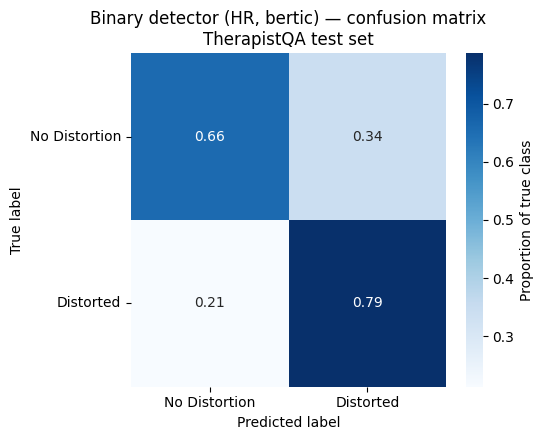

Saved figure to /content/drive/MyDrive/thesis_stage2/results/binary_therapistqa_tqa_binary_hr_bertic_confusion_matrix.png


In [12]:
# 10. Confusion matrix plot
import matplotlib.pyplot as plt
import seaborn as sns

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm_norm,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=["No Distortion", "Distorted"],
    yticklabels=["No Distortion", "Distorted"],
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"Binary detector (HR, {MODEL_TAG}) — confusion matrix\nTherapistQA test set")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

fig_path = RESULTS_DIR / f"binary_therapistqa_{RUN_TAG}_confusion_matrix.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {fig_path}")

Cross-evaluation: HR binary detector on translated PatternReframe test

In [13]:
# Load PR augmented test (Croatian) and run the HR binary detector on it.
import pandas as pd
import numpy as np
import torch
from torch.nn.functional import softmax
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
)

# === Load the PR augmented bilingual test split ===
# This file has both `thought` (EN) and `thought_hr` (HR). We use HR.
PR_TEST = PROJECT_ROOT / "patternreframe_bilingual_test_aug_v1_balanced.csv"
# If the augmented bilingual file does not exist (only the non-augmented one
# was translated in Phase D), fall back to the non-augmented PR bilingual test.
# In that case, all rows are Distorted (no ND samples), and the recall on the
# Distorted class is the relevant number.
if not PR_TEST.exists():
    PR_TEST = PROJECT_ROOT / "patternreframe_bilingual_test.csv"
    print(f"Augmented HR test not found; falling back to non-augmented: {PR_TEST}")
else:
    print(f"Loading PR augmented HR test from: {PR_TEST}")

pr = pd.read_csv(PR_TEST).dropna(subset=["thought_hr"])
pr["text"]     = pr["thought_hr"].astype(str)
# The `pattern` column carries the original English label. If a row's pattern
# is "No Distortion" (only present in augmented splits) label is 0; else 1.
pr["label"]    = (pr["pattern"] != "No Distortion").astype(int)
pr["category"] = pr["pattern"]
print(f"PR HR test: {len(pr)} rows, label distribution: {pr['label'].value_counts().to_dict()}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

preds, probs = [], []
BS = 32
with torch.no_grad():
    for i in range(0, len(pr), BS):
        batch_texts = pr["text"].iloc[i:i+BS].tolist()
        enc = tokenizer(
            batch_texts, truncation=True, max_length=MAX_LEN,
            padding=True, return_tensors="pt"
        ).to(device)
        logits = model(**enc).logits
        p = softmax(logits, dim=-1).cpu().numpy()
        preds.extend(np.argmax(p, axis=-1).tolist())
        probs.extend(p[:, 1].tolist())

pr_eval = pr.copy()
pr_eval["pred"]            = preds
pr_eval["prob_distorted"]  = probs

Augmented HR test not found; falling back to non-augmented: /content/drive/MyDrive/thesis_stage2/patternreframe_bilingual_test.csv
PR HR test: 6807 rows, label distribution: {1: 6807}


In [14]:
# === Headline cross-domain metrics ===
print("=== Cross-eval: HR TQA binary detector on HR PR test ===")
print(f"Accuracy:    {accuracy_score(pr_eval['label'], pr_eval['pred']):.4f}")
print(f"Weighted F1: {f1_score(pr_eval['label'], pr_eval['pred'], average='weighted'):.4f}")
print(f"Macro F1:    {f1_score(pr_eval['label'], pr_eval['pred'], average='macro'):.4f}")
print()
if pr_eval["label"].nunique() > 1:
    print(classification_report(
        pr_eval["label"], pr_eval["pred"],
        target_names=["No Distortion", "Distorted"],
        digits=4, zero_division=0,
    ))
    print("Confusion matrix:")
    print(confusion_matrix(pr_eval["label"], pr_eval["pred"]))
else:
    # Single-class case (non-augmented PR test, all Distorted)
    print("Only one class present in this PR test (no ND records).")
    print(f"Recall on Distorted: {(pr_eval['pred'] == 1).mean():.4f}")

# === Confidence-gap diagnostic ===
if pr_eval["label"].nunique() > 1:
    nd_mask = pr_eval["label"] == 0
    mean_prob_nd = pr_eval.loc[nd_mask,  "prob_distorted"].mean()
    mean_prob_d  = pr_eval.loc[~nd_mask, "prob_distorted"].mean()
    nd_called_d  = (pr_eval.loc[nd_mask, "pred"] == 1).mean()
    print(f"\nOf the {nd_mask.sum()} PR-HR ND records, {nd_called_d:.1%} were predicted as Distorted.")
    print(f"Mean prob_distorted on PR-HR ND records: {mean_prob_nd:.3f}")
    print(f"Mean prob_distorted on PR-HR D records:  {mean_prob_d:.3f}")
    print(f"Confidence gap (D - ND): {mean_prob_d - mean_prob_nd:+.3f}")

# === Per-category recall ===
print("\nPer-category recall on PR HR test:")
per_category = {}
for cat in sorted(pr_eval["category"].unique()):
    sub = pr_eval[pr_eval["category"] == cat]
    if cat == "No Distortion":
        per_category[cat] = float((sub["pred"] == 0).mean())
    else:
        per_category[cat] = float((sub["pred"] == 1).mean())
for cat, rec in per_category.items():
    print(f"  {cat:60s}  {rec:.4f}")

=== Cross-eval: HR TQA binary detector on HR PR test ===
Accuracy:    0.4102
Weighted F1: 0.5817
Macro F1:    0.2909

Only one class present in this PR test (no ND records).
Recall on Distorted: 0.4102

Per-category recall on PR HR test:
  Black-and-white or polarized thinking / All or nothing thinking  0.4165
  Catastrophizing                                               0.4518
  Discounting the positive                                      0.1615
  Jumping to conclusions: Fortune-telling                       0.3966
  Jumping to conclusions: mind reading                          0.6624
  Labeling and mislabeling                                      0.6203
  Mental filtering                                              0.3394
  Overgeneralization                                            0.4346
  Personalization                                               0.5145
  Should statements                                             0.0885


In [15]:
# Save cross-evaluation results
cross_results = {
    "model": MODEL_NAME,
    "language": "hr",
    "trained_on": "therapistqa_hr_train",
    "evaluated_on": str(PR_TEST.name),
    "accuracy": float(accuracy_score(pr_eval["label"], pr_eval["pred"])),
    "f1_weighted": float(f1_score(pr_eval["label"], pr_eval["pred"], average="weighted")),
    "f1_macro": float(f1_score(pr_eval["label"], pr_eval["pred"], average="macro")),
    "per_category_recall": per_category,
    "n": len(pr_eval),
}

if pr_eval["label"].nunique() > 1:
    cross_results["confusion_matrix"] = confusion_matrix(pr_eval["label"], pr_eval["pred"]).tolist()
    cross_results["mean_prob_distorted_on_ND"] = float(mean_prob_nd)
    cross_results["mean_prob_distorted_on_D"]  = float(mean_prob_d)
    cross_results["confidence_gap"]            = float(mean_prob_d - mean_prob_nd)

cross_path = RESULTS_DIR / f"binary_therapistqa_{RUN_TAG}_cross_pr.json"
with open(cross_path, "w") as f:
    json.dump(cross_results, f, indent=2)
preds_pr_path = RESULTS_DIR / f"binary_therapistqa_{RUN_TAG}_cross_pr_predictions.csv"
pr_eval.to_csv(preds_pr_path, index=False)

print(f"Saved cross-eval metrics to     {cross_path}")
print(f"Saved cross-eval predictions to {preds_pr_path}")

Saved cross-eval metrics to     /content/drive/MyDrive/thesis_stage2/results/binary_therapistqa_tqa_binary_hr_bertic_cross_pr.json
Saved cross-eval predictions to /content/drive/MyDrive/thesis_stage2/results/binary_therapistqa_tqa_binary_hr_bertic_cross_pr_predictions.csv


Side-by-side with the English run

In [16]:
# === Look for the English equivalent results file and print a comparison ===
candidates = list(RESULTS_DIR.glob("binary_patternreframe_tqa_binary_test_metrics.json")) \
           + list(RESULTS_DIR.glob("binary_therapistqa_tqa_binary_test_metrics.json"))

if not candidates:
    print("No English binary results JSON found in results/. Skip comparison.")
else:
    en_path = candidates[0]
    print(f"Comparing against English run: {en_path.name}")
    en_res = json.load(open(en_path))

    def get(d, key, default=""):
        return d.get("test_metrics", {}).get(key, default)

    keys = ["eval_accuracy", "eval_f1_weighted", "eval_f1_macro",
            "eval_precision_distorted", "eval_recall_distorted", "eval_f1_distorted"]

    print(f"\n{'Metric':<28} {'EN':>10} {'HR':>10} {'Δ':>10}")
    print("-" * 62)
    for k in keys:
        en_v = get(en_res, k)
        hr_v = test_metrics.get(k, "")
        try:
            delta = float(hr_v) - float(en_v)
            print(f"{k:<28} {float(en_v):>10.4f} {float(hr_v):>10.4f} {delta:>+10.4f}")
        except (TypeError, ValueError):
            print(f"{k:<28} {str(en_v):>10} {str(hr_v):>10}")

    # Per-category recall comparison
    print("\nPer-category recall (TQA test):")
    en_per_cat = en_res.get("per_category_recall", {})
    cats_all = sorted(set(en_per_cat) | set(per_category_recall))
    print(f"{'Category':<55} {'EN':>8} {'HR':>8} {'Δ':>8}")
    print("-" * 80)
    for cat in cats_all:
        en_v = en_per_cat.get(cat, float('nan'))
        hr_v = per_category_recall.get(cat, float('nan'))
        try:
            delta = hr_v - en_v
            print(f"{cat:<55} {en_v:>8.4f} {hr_v:>8.4f} {delta:>+8.4f}")
        except Exception:
            print(f"{cat:<55} {en_v} {hr_v}")

No English binary results JSON found in results/. Skip comparison.
